# SuperEstela · Validación fuera de muestra (Stuff+)
Entrena el modelo final **sin `same_hand`** (12 features) y corre las tres validaciones del documento técnico:

1. **Pitcher holdout** (5 pliegues agrupados por lanzador): referencia y escala (μ, σ por tipo).
2. **Season holdout**: `SEASON_SPLITS` (2026 se prueba entrenando con 2024–2025).
3. **Park holdout**: entrenar sin una categoría de altitud y probar en ella (principal: altitud extrema).
4. **S7**: modelo nulo por conteo contra el modelo, con bootstrap por lanzadores.

Lee `Stuffbueno.parquet` (ya con todas las features). Guarda figuras a 300 dpi, tablas agregadas y pies de figura en `validacion_out/`. **No exporta datos a nivel lanzamiento.**
> Este notebook valida el **maestro** (multiclase, 7 clases, mismas features que FINAL_v1 menos `same_hand`). El estudiante monótono publicado se destila de este maestro.

In [1]:
import os, json, time, hashlib, warnings
import numpy as np, pandas as pd, xgboost as xgb
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
warnings.filterwarnings("ignore")

# ------------------------------------------------------------------ CONFIG
DATA_PATH = os.environ.get("STUFF_PARQUET", "Stuffbueno.parquet")
OUT_DIR   = "validacion_out"; FIG_DIR = f"{OUT_DIR}/figuras"
os.makedirs(FIG_DIR, exist_ok=True)
LOG_MLFLOW = False                       # True: registra métricas y figuras en MLflow
MLFLOW_URI, MLFLOW_EXP = "sqlite:///mlflow.db", "superestela/A-target/validacion-holdouts"
N_BOOT = 300

GROUP, GAME, PT, ALT, YEAR = "pitcher_anon_id", "game_anon_id", "AutoPitchType", "altitude_category", "year"
FEATURES = ["RelSpeed", "RelHeight", "RelSide_m", "Extension",
            "InducedVertBreak", "HorzBreak_m",
            "SpinRate", "SpinAxis_sin", "SpinAxis_cos",
            "speed_diff_env", "ivb_diff_env", "hb_diff_env"]          # 12 features, sin same_hand
CORE = ["RelSpeed", "InducedVertBreak", "HorzBreak_m"]
CLASSES = ["Whiff", "Foul", "Weak", "Out", "Single", "XBH", "HomeRun"]  # swing_cq
CMAP = {c: i for i, c in enumerate(CLASSES)}
WEAK_EV = 71.0
PARAMS = dict(eta=0.05, max_depth=4, min_child_weight=30, subsample=0.8, colsample_bytree=0.8, reg_lambda=5.0)
ROUNDS, ES_ROUNDS, VAL_FRAC, N_FOLDS, SEED = 250, 20, 0.1, 5, 42
EXCLUDE = ["Other", "Knuckleball", "Undefined", "Splitter", "Sweeper", "OneSeamFastBall", "TwoSeamFastBall"]
MIN_ROWS = 3000

SEASON_SPLITS = {2024: [2025, 2026], 2025: [2024, 2026], 2026: [2024, 2025]}
PARK_SPLITS = {   # categoría de prueba -> categorías de entrenamiento
    "Extreme Altitude": ["No Altitude", "Medium Altitude"],
    "Medium Altitude":  ["No Altitude", "Extreme Altitude"],
    "No Altitude":      ["Medium Altitude", "Extreme Altitude"],
}
ALT_ES = {"Extreme Altitude": "altitud extrema", "Medium Altitude": "altitud media", "No Altitude": "nivel del mar"}
BASE_MAP = {"StrikeSwinging": "Whiff", "FoulBall": "Foul", "Out": "Out", "Single": "Single",
            "Double": "XBH", "Triple": "XBH", "HomeRun": "HomeRun"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10, "axes.grid": True, "grid.alpha": .25})
ACCENT = "#B01C2E"

## 1. Carga y preparación

In [2]:
df = pd.read_parquet(DATA_PATH)
for c in (GROUP, GAME, PT, ALT, "event_type"):
    if c in df.columns and str(df[c].dtype) == "category":
        df[c] = df[c].astype(object)

NEED = FEATURES + [GROUP, GAME, PT, ALT, YEAR, "event_type", "ExitSpeed", "delta_run_exp",
                   "has_rv", "valid_hand", "Balls", "Strikes"]
falta = [c for c in NEED if c not in df.columns]
if falta:                                    # por si el parquet no trae los diferenciales por entorno
    try:
        import experimentos_stuff as ex
        df = ex.prepare_extra_features(df)
        falta = [c for c in NEED if c not in df.columns]
    except Exception as e:
        print("No se pudo completar con experimentos_stuff:", e)
assert not falta, f"Faltan columnas en el parquet: {falta}"

D = df[NEED].copy()
base = D["event_type"].map(BASE_MAP).astype(object)
es = pd.to_numeric(D["ExitSpeed"], errors="coerce")
bip = base.isin(["Out", "Single", "XBH", "HomeRun"])
D["label"] = base.where(~(bip & (es < WEAK_EV)), "Weak")      # swing_cq; NaN si no hubo swing
D = D[D["valid_hand"].astype(bool) & D[CORE].notna().all(axis=1)].copy()
TYPES = [p for p, n in D[PT].value_counts().items() if p not in EXCLUDE and n >= MIN_ROWS]
D = D[D[PT].isin(TYPES)].reset_index(drop=True)
D["is_swing"] = D["label"].notna()
D["y"] = D["label"].map(CMAP)
D["rv_real"] = D["delta_run_exp"].where(D["has_rv"].astype(bool))
D["Balls"] = pd.to_numeric(D["Balls"], errors="coerce"); D["Strikes"] = pd.to_numeric(D["Strikes"], errors="coerce")

# pliegues por lanzador (igual que la rejilla de experimentos)
uniq = np.sort(D[GROUP].dropna().unique())
perm = np.random.default_rng(SEED).permutation(len(uniq))
D["fold"] = D[GROUP].map({g: i % N_FOLDS for i, g in enumerate(uniq[perm])})

DATA_HASH = hashlib.sha1(open(DATA_PATH, "rb").read()).hexdigest()[:12] if os.path.exists(DATA_PATH) else "sin_hash"
print("Tipos:", TYPES)
print(f"Lanzamientos: {len(D):,} · swings: {int(D.is_swing.sum()):,} · lanzadores: {D[GROUP].nunique():,}")
display(D.groupby([YEAR, ALT]).size().unstack(fill_value=0))
display(D.groupby(PT)["is_swing"].agg(["size", "sum"]).rename(columns={"size": "lanzamientos", "sum": "swings"}))

Tipos: ['Four-Seam', 'Slider', 'Sinker', 'Changeup', 'Curveball', 'Cutter']
Lanzamientos: 624,674 · swings: 291,543 · lanzadores: 1,078


altitude_category,Extreme Altitude,Medium Altitude,No Altitude
year,,,
2024,65842,60396,113908
2025,71352,65294,115099
2026,42466,27538,60717


,lanzamientos,swings
AutoPitchType,,
Changeup,78432,38316
Curveball,53771,23257
Cutter,26374,12850
Four-Seam,216850,100149
Sinker,110524,50184
Slider,138723,66787


## 2. Funciones de entrenamiento y evaluación
Los valores de carrera por clase y la tabla del nulo por conteo se calculan **solo con el entrenamiento** de cada partición (sin fuga).

In [3]:
def fit_predict(tr, te):
    """Entrena un XGBoost multiclase (swing_cq) y devuelve (P sobre te, booster, n_trees)."""
    trs = tr[tr["is_swing"]]
    pit = trs[GROUP].unique()
    rng = np.random.default_rng(SEED)
    val_p = set(rng.choice(pit, size=max(1, int(len(pit) * VAL_FRAC)), replace=False))
    isv = trs[GROUP].isin(val_p).to_numpy()
    X = trs[FEATURES].astype("float32")
    dtr = xgb.DMatrix(X[~isv], label=trs["y"].to_numpy()[~isv])
    dva = xgb.DMatrix(X[isv],  label=trs["y"].to_numpy()[isv])
    p = dict(PARAMS, objective="multi:softprob", num_class=len(CLASSES), eval_metric="mlogloss",
             tree_method="hist", seed=SEED)
    bst = xgb.train(p, dtr, num_boost_round=ROUNDS, evals=[(dtr, "train"), (dva, "val")],
                    early_stopping_rounds=ES_ROUNDS, verbose_eval=False)
    n = bst.best_iteration + 1
    P = bst.predict(xgb.DMatrix(te[FEATURES].astype("float32")), iteration_range=(0, n)).reshape(len(te), -1)
    return P, bst, n


def run_split(name, kind, train_mask, test_mask):
    """Entrena un modelo por tipo con train_mask y puntúa TODOS los pitcheos de test_mask."""
    parts = []
    for pt in TYPES:
        sub = D[D[PT] == pt]
        tr = sub[train_mask.loc[sub.index].to_numpy()]
        te = sub[test_mask.loc[sub.index].to_numpy()]
        trs = tr[tr["is_swing"]]
        if len(trs) < 2000 or te["is_swing"].sum() < 200:
            print(f"  {name} · {pt}: muestra insuficiente (train={len(trs)}, test swings={int(te.is_swing.sum())})")
            continue
        P, bst, n = fit_predict(tr, te)
        v = trs[trs["rv_real"].notna()].groupby("label")["rv_real"].mean().reindex(CLASSES).fillna(0.0).to_numpy()
        cm = trs[trs["rv_real"].notna()].groupby(["Balls", "Strikes"])["rv_real"].mean().rename("null_rv").reset_index()
        nul = te[["Balls", "Strikes"]].merge(cm, on=["Balls", "Strikes"], how="left")["null_rv"].to_numpy()
        nul = np.where(np.isnan(nul), trs["rv_real"].mean(), nul)
        prior = np.bincount(trs["y"].astype(int), minlength=len(CLASSES)) / len(trs)
        y = te["y"].to_numpy()
        yi = np.where(np.isnan(y), 0, y).astype(int)
        r = pd.DataFrame({
            "pitcher": te[GROUP].to_numpy(), "game": te[GAME].to_numpy(), "pt": pt, "year": te[YEAR].to_numpy(),
            "alt": te[ALT].to_numpy(), "is_swing": te["is_swing"].to_numpy(),
            "is_whiff": (te["label"] == "Whiff").to_numpy(), "rv_real": te["rv_real"].to_numpy(),
            "xrv": P @ v, "null_rv": nul, "p_whiff": P[:, CMAP["Whiff"]],
            "p_true": np.where(te["is_swing"], P[np.arange(len(te)), yi], np.nan),
            "p_base": np.where(te["is_swing"], prior[yi], np.nan),
            "n_train": len(trs), "n_trees": n, "split": name, "kind": kind})
        parts.append(r)
        print(f"  {name} · {pt}: train={len(trs):,} swings · test={len(te):,} pitcheos · árboles={n}")
    return pd.concat(parts, ignore_index=True)


def metrics_by_type(res):
    rows = []
    for (s, k, pt), g in res.groupby(["split", "kind", "pt"]):
        sw = g[g["is_swing"]]
        ll, bl = -np.log(np.clip(sw["p_true"], 1e-9, 1)).mean(), -np.log(np.clip(sw["p_base"], 1e-9, 1)).mean()
        auc = roc_auc_score(sw["is_whiff"], sw["p_whiff"]) if sw["is_whiff"].nunique() == 2 else np.nan
        rows.append(dict(split=s, kind=k, pitch_type=pt, n_swings_test=len(sw), n_train=int(g["n_train"].iloc[0]),
                         logloss=ll, logloss_base=bl, improve_pct=100 * (bl - ll) / bl, auc_whiff=auc))
    return pd.DataFrame(rows)


def decile_calibration(res, n=10):
    t = res[res["is_swing"] & res["rv_real"].notna()][["xrv", "rv_real"]]
    t = t.assign(bin=pd.qcut(t["xrv"], n, labels=False, duplicates="drop"))
    g = t.groupby("bin").agg(xrv=("xrv", "mean"), real=("rv_real", "mean")).reset_index()
    return g, float(np.polyfit(g["xrv"], g["real"], 1)[0])


def split_half(res, min_n=30):
    d = res.copy()
    d["half"] = pd.factorize(d["game"])[0] % 2
    g = d.groupby(["pitcher", "pt", "half"])["stuff"].agg(["mean", "size"]).unstack("half").dropna()
    g = g[(g[("size", 0)] >= min_n) & (g[("size", 1)] >= min_n)]
    rs = []
    for pt, gg in g.groupby(level="pt"):
        if len(gg) >= 10:
            r = np.corrcoef(gg[("mean", 0)], gg[("mean", 1)])[0, 1]
            rs.append(2 * r / (1 + r))
    return float(np.mean(rs)) if rs else np.nan

## 3. Pitcher holdout (referencia y escala)

In [4]:
t0 = time.time()
res_pitcher = pd.concat([run_split("Lanzador", "pitcher", D["fold"] != k, D["fold"] == k) for k in range(N_FOLDS)],
                        ignore_index=True)
# el reporte por tipo se calcula sobre el OOF completo (un solo "split")
res_pitcher["split"] = "Lanzador (5 pliegues)"
# escala: μ y σ del xRV fuera de pliegue, por tipo
MU = res_pitcher.groupby("pt")["xrv"].mean(); SD = res_pitcher.groupby("pt")["xrv"].std()
def add_stuff(r):
    r["stuff"] = 100 - 10 * (r["xrv"] - r["pt"].map(MU)) / r["pt"].map(SD)
    return r
res_pitcher = add_stuff(res_pitcher)
print(f"\nListo en {time.time()-t0:.0f}s")
display(pd.DataFrame({"mu_xrv": MU, "sd_xrv": SD}).round(4))

  Lanzador · Four-Seam: train=80,164 swings · test=43,252 pitcheos · árboles=146
  Lanzador · Slider: train=53,710 swings · test=27,024 pitcheos · árboles=96
  Lanzador · Sinker: train=41,819 swings · test=18,666 pitcheos · árboles=87
  Lanzador · Changeup: train=31,423 swings · test=14,217 pitcheos · árboles=72
  Lanzador · Curveball: train=18,637 swings · test=10,695 pitcheos · árboles=54
  Lanzador · Cutter: train=9,731 swings · test=6,421 pitcheos · árboles=19
  Lanzador · Four-Seam: train=79,906 swings · test=43,519 pitcheos · árboles=145
  Lanzador · Slider: train=53,213 swings · test=28,228 pitcheos · árboles=78
  Lanzador · Sinker: train=39,976 swings · test=22,367 pitcheos · árboles=81
  Lanzador · Changeup: train=31,080 swings · test=14,955 pitcheos · árboles=93
  Lanzador · Curveball: train=18,337 swings · test=11,203 pitcheos · árboles=74
  Lanzador · Cutter: train=10,702 swings · test=4,304 pitcheos · árboles=49
  Lanzador · Four-Seam: train=77,438 swings · test=49,263 pit

,mu_xrv,sd_xrv
pt,,
Changeup,-0.0122,0.0161
Curveball,-0.0159,0.0130
Cutter,-0.0147,0.0117
Four-Seam,-0.0081,0.0206
Sinker,-0.0040,0.0122
Slider,-0.0172,0.0113


## 4. Season holdout

In [5]:
res_season = []
for test_year, train_years in SEASON_SPLITS.items():
    nm = f"Temporada {test_year}"
    res_season.append(run_split(nm, "season", D[YEAR].isin(train_years), D[YEAR].eq(test_year)))
res_season = add_stuff(pd.concat(res_season, ignore_index=True))

  Temporada 2024 · Four-Seam: train=60,308 swings · test=84,845 pitcheos · árboles=124
  Temporada 2024 · Slider: train=41,177 swings · test=52,581 pitcheos · árboles=80
  Temporada 2024 · Sinker: train=31,465 swings · test=40,695 pitcheos · árboles=61
  Temporada 2024 · Changeup: train=23,261 swings · test=30,399 pitcheos · árboles=53
  Temporada 2024 · Curveball: train=13,764 swings · test=21,775 pitcheos · árboles=69
  Temporada 2024 · Cutter: train=8,048 swings · test=9,851 pitcheos · árboles=34
  Temporada 2025 · Four-Seam: train=59,588 swings · test=88,828 pitcheos · árboles=137
  Temporada 2025 · Slider: train=40,091 swings · test=55,531 pitcheos · árboles=37
  Temporada 2025 · Sinker: train=29,948 swings · test=44,909 pitcheos · árboles=44
  Temporada 2025 · Changeup: train=23,267 swings · test=30,901 pitcheos · árboles=50
  Temporada 2025 · Curveball: train=14,351 swings · test=20,814 pitcheos · árboles=10
  Temporada 2025 · Cutter: train=7,568 swings · test=10,765 pitcheos · 

## 5. Park holdout (por categoría de altitud)

In [6]:
res_park = []
for test_cat, train_cats in PARK_SPLITS.items():
    nm = f"Estadio: {ALT_ES[test_cat]}"
    res_park.append(run_split(nm, "park", D[ALT].isin(train_cats), D[ALT].eq(test_cat)))
res_park = add_stuff(pd.concat(res_park, ignore_index=True))

  Estadio: altitud extrema · Four-Seam: train=71,805 swings · test=61,734 pitcheos · árboles=150
  Estadio: altitud extrema · Slider: train=46,049 swings · test=42,536 pitcheos · árboles=94
  Estadio: altitud extrema · Sinker: train=35,957 swings · test=31,665 pitcheos · árboles=68
  Estadio: altitud extrema · Changeup: train=28,930 swings · test=19,247 pitcheos · árboles=68
  Estadio: altitud extrema · Curveball: train=16,675 swings · test=14,382 pitcheos · árboles=30
  Estadio: altitud extrema · Cutter: train=7,890 swings · test=10,096 pitcheos · árboles=36
  Estadio: altitud media · Four-Seam: train=74,614 swings · test=55,286 pitcheos · árboles=104
  Estadio: altitud media · Slider: train=49,284 swings · test=36,101 pitcheos · árboles=57
  Estadio: altitud media · Sinker: train=39,302 swings · test=23,563 pitcheos · árboles=68
  Estadio: altitud media · Changeup: train=29,549 swings · test=17,625 pitcheos · árboles=87
  Estadio: altitud media · Curveball: train=17,105 swings · test

## 6. Resumen de métricas

In [7]:
ALL = pd.concat([res_pitcher, res_season, res_park], ignore_index=True)
M = metrics_by_type(ALL)
ORDER = ["Lanzador (5 pliegues)"] + [f"Temporada {y}" for y in SEASON_SPLITS] + [f"Estadio: {ALT_ES[c]}" for c in PARK_SPLITS]
M["split"] = pd.Categorical(M["split"], ORDER, ordered=True)
M = M.sort_values(["split", "pitch_type"]).reset_index(drop=True)

rows = []
for s in ORDER:
    r = ALL[ALL["split"] == s]
    cal, slope = decile_calibration(r)
    rows.append(dict(split=s, calibracion_pendiente=slope, split_half=split_half(r),
                     improve_pct_medio=M.loc[M["split"] == s, "improve_pct"].mean(),
                     auc_whiff_medio=M.loc[M["split"] == s, "auc_whiff"].mean()))
SUM = pd.DataFrame(rows)
M.round(4).to_csv(f"{OUT_DIR}/validacion_por_tipo.csv", index=False)
SUM.round(4).to_csv(f"{OUT_DIR}/validacion_resumen.csv", index=False)
display(SUM.round(3))
display(M.pivot(index="pitch_type", columns="split", values="improve_pct").round(2)[ORDER])

,split,calibracion_pendiente,split_half,improve_pct_medio,auc_whiff_medio
0,Lanzador (5 pliegues),0.961,0.952,0.774,0.588
1,Temporada 2024,0.882,0.941,0.752,0.590
2,Temporada 2025,1.107,0.932,0.661,0.589
3,Temporada 2026,0.988,0.928,0.718,0.585
4,Estadio: altitud extrema,0.796,0.952,0.735,0.583
5,Estadio: altitud media,1.034,0.964,0.695,0.582
6,Estadio: nivel del mar,0.619,0.949,0.823,0.591


split,Lanzador (5 pliegues),Temporada 2024,Temporada 2025,Temporada 2026,Estadio: altitud extrema,Estadio: altitud media,Estadio: nivel del mar
pitch_type,,,,,,,
Changeup,1.09,1.03,1.16,0.87,0.91,0.96,1.04
Curveball,0.36,0.53,0.22,0.41,0.52,0.20,0.56
Cutter,0.62,0.56,0.06,0.65,0.67,0.75,0.61
Four-Seam,1.47,1.36,1.49,1.45,1.25,1.26,1.61
Sinker,0.51,0.47,0.49,0.47,0.48,0.42,0.50
Slider,0.60,0.56,0.56,0.47,0.59,0.58,0.61


## 7. S7 · modelo nulo por conteo
Error cuadrático medio (RMSE) sobre el run value de cada swing. **Nulo**: promedio por conteo (del entrenamiento). **Solo modelo**: xRV recalibrado linealmente. **Conteo + modelo**: regresión con ambos. Las recalibraciones se ajustan con validación cruzada agrupada por lanzador. Δ < 0 significa que mejora al nulo; el IC95% sale de un bootstrap por lanzadores.

In [13]:
def s7(res, n_boot=N_BOOT, seed=0):
    r = res[
        res["is_swing"]
        & res["rv_real"].notna()
        & res["null_rv"].notna()
        & res["xrv"].notna()
        & res["pitcher"].notna()
    ].copy()

    r["pitcher"] = r["pitcher"].astype(str)
    r = r.reset_index(drop=True)

    if r["pitcher"].nunique() < 5:
        return {
            "n_swings": len(r),
            "rmse_nulo": np.nan,
            "rmse_modelo": np.nan,
            "rmse_conteo_modelo": np.nan,
            "d_modelo": np.nan,
            "d_modelo_lo": np.nan,
            "d_modelo_hi": np.nan,
            "d_conteo_modelo": np.nan,
            "d_cm_lo": np.nan,
            "d_cm_hi": np.nan,
        }

    y = r["rv_real"].to_numpy()

    designs = {
        "modelo": np.c_[
            np.ones(len(r)),
            r["xrv"].to_numpy(),
        ],
        "conteo_modelo": np.c_[
            np.ones(len(r)),
            r["null_rv"].to_numpy(),
            r["xrv"].to_numpy(),
        ],
    }

    err = {
        "nulo": (
            y - r["null_rv"].to_numpy()
        ) ** 2
    }

    for k, X in designs.items():
        pred = np.zeros(len(r))

        for a, b in GroupKFold(
            n_splits=5
        ).split(
            X,
            y,
            groups=r["pitcher"],
        ):
            beta = np.linalg.lstsq(
                X[a],
                y[a],
                rcond=None,
            )[0]
            pred[b] = X[b] @ beta

        err[k] = (y - pred) ** 2

    g = (
        pd.DataFrame(
            {
                "p": r["pitcher"],
                "n": 1.0,
                **err,
            }
        )
        .groupby("p")
        .sum()
    )

    arr = g[
        [
            "n",
            "nulo",
            "modelo",
            "conteo_modelo",
        ]
    ].to_numpy()

    rm = lambda s: np.sqrt(s[1:] / s[0])
    est = rm(arr.sum(axis=0))

    rng = np.random.default_rng(seed)
    bs = np.array(
        [
            rm(
                arr[
                    rng.integers(
                        0,
                        len(arr),
                        len(arr),
                    )
                ].sum(axis=0)
            )
            for _ in range(n_boot)
        ]
    )

    d_mod = bs[:, 1] - bs[:, 0]
    d_cm = bs[:, 2] - bs[:, 0]

    return {
        "n_swings": len(r),
        "rmse_nulo": est[0],
        "rmse_modelo": est[1],
        "rmse_conteo_modelo": est[2],
        "d_modelo": est[1] - est[0],
        "d_modelo_lo": np.percentile(d_mod, 2.5),
        "d_modelo_hi": np.percentile(d_mod, 97.5),
        "d_conteo_modelo": est[2] - est[0],
        "d_cm_lo": np.percentile(d_cm, 2.5),
        "d_cm_hi": np.percentile(d_cm, 97.5),
    }

In [14]:
S7 = pd.DataFrame(
    [
        {
            "split": s,
            **s7(ALL[ALL["split"] == s]),
        }
        for s in ORDER
    ]
)

S7.round(5).to_csv(
    f"{OUT_DIR}/s7_resumen.csv",
    index=False,
)

display(S7.round(5))

,split,n_swings,rmse_nulo,rmse_modelo,rmse_conteo_modelo,d_modelo,d_modelo_lo,d_modelo_hi,d_conteo_modelo,d_cm_lo,d_cm_hi
0,Lanzador (5 pliegues),290482,0.30200,0.30208,0.30163,0.00008,-0.00000,0.00019,-0.00036,-0.00042,-0.00031
1,Temporada 2024,113520,0.29788,0.29792,0.29750,0.00004,-0.00012,0.00021,-0.00039,-0.00048,-0.00029
2,Temporada 2025,116730,0.30670,0.30678,0.30633,0.00008,-0.00008,0.00022,-0.00038,-0.00047,-0.00028
3,Temporada 2026,60232,0.30064,0.30075,0.30033,0.00010,-0.00009,0.00031,-0.00032,-0.00042,-0.00020
4,Estadio: altitud extrema,82799,0.31660,0.31628,0.31589,-0.00032,-0.00053,-0.00010,-0.00071,-0.00086,-0.00057
5,Estadio: altitud media,71226,0.31103,0.31112,0.31056,0.00010,-0.00012,0.00032,-0.00047,-0.00063,-0.00035
6,Estadio: nivel del mar,135745,0.28858,0.28787,0.28750,-0.00071,-0.00091,-0.00052,-0.00108,-0.00122,-0.00094


## 8. Modelo con todos los datos: importancia de las 12 features

In [9]:
imp_rows = []
for pt in TYPES:
    sub = D[D[PT] == pt]
    _, bst, _ = fit_predict(sub, sub.head(10))
    sc = bst.get_score(importance_type="total_gain")
    tot = sum(sc.values())
    for f in FEATURES:
        imp_rows.append(dict(pitch_type=pt, feature=f, gain_pct=100 * sc.get(f, 0.0) / tot))
IMP = pd.DataFrame(imp_rows)
IMP.round(3).to_csv(f"{OUT_DIR}/importancia_12features.csv", index=False)
display(IMP.pivot(index="feature", columns="pitch_type", values="gain_pct").round(1))

pitch_type,Changeup,Curveball,Cutter,Four-Seam,Sinker,Slider
feature,,,,,,
Extension,6.0,10.6,7.9,5.1,7.2,5.9
HorzBreak_m,8.8,8.4,10.2,5.0,7.7,7.8
InducedVertBreak,6.1,9.4,7.2,18.8,11.0,9.0
RelHeight,6.0,9.0,8.2,8.0,8.9,6.0
RelSide_m,6.2,8.2,6.0,6.7,8.5,6.7
RelSpeed,8.5,15.1,8.6,10.5,8.6,9.0
SpinAxis_cos,4.3,4.3,5.1,4.3,5.7,6.9
SpinAxis_sin,3.9,4.3,8.3,4.1,4.5,5.7
SpinRate,6.3,6.1,8.2,6.7,7.4,6.8


## 9. Altitud: ΔStuff+ por tipo y transferencia del park holdout

In [10]:
# ΔStuff+ (altitud extrema − nivel del mar), mismo lanzador y tipo, con la escala fuera de pliegue
def pitcher_means(r, env, min_n=40):
    g = r[r["alt"] == env].groupby(["pitcher", "pt"])["stuff"].agg(["mean", "size"])
    return g[g["size"] >= min_n]["mean"]
sea, ext = pitcher_means(res_pitcher, "No Altitude"), pitcher_means(res_pitcher, "Extreme Altitude")
dd = (ext - sea).dropna().rename("delta").reset_index()
rng = np.random.default_rng(1)
rows = []
for pt, g in dd.groupby("pt"):
    v = g["delta"].to_numpy()
    bs = [v[rng.integers(0, len(v), len(v))].mean() for _ in range(N_BOOT)]
    rows.append(dict(pitch_type=pt, n_pitchers=len(v), delta_stuff=v.mean(),
                     lo=np.percentile(bs, 2.5), hi=np.percentile(bs, 97.5)))
DELTA = pd.DataFrame(rows).sort_values("delta_stuff").reset_index(drop=True)
DELTA.round(3).to_csv(f"{OUT_DIR}/delta_stuff_altitud_por_tipo.csv", index=False)
display(DELTA.round(2))

# Park holdout: ¿el modelo que NUNCA vio altitud extrema ordena igual a los lanzadores allí?
a = pitcher_means(res_pitcher, "Extreme Altitude").rename("oof")
b = pitcher_means(res_park[res_park["split"] == "Estadio: altitud extrema"], "Extreme Altitude").rename("sin_altitud")
PK = pd.concat([a, b], axis=1).dropna().reset_index()
r_park = float(np.corrcoef(PK["oof"], PK["sin_altitud"])[0, 1]) if len(PK) > 5 else np.nan
print(f"Lanzador-tipo en altitud extrema: n={len(PK)}, r(OOF, park holdout)={r_park:.3f}, "
      f"sesgo medio (park − OOF)={ (PK['sin_altitud']-PK['oof']).mean():.2f}")

,pitch_type,n_pitchers,delta_stuff,lo,hi
0,Sinker,158,-10.12,-10.73,-9.59
1,Four-Seam,328,-8.41,-8.82,-8.00
2,Curveball,64,-6.31,-7.44,-5.18
3,Slider,226,-5.64,-6.13,-5.25
4,Changeup,104,-5.04,-5.78,-4.34
5,Cutter,25,-1.94,-3.16,-0.31


Lanzador-tipo en altitud extrema: n=1243, r(OOF, park holdout)=0.795, sesgo medio (park − OOF)=2.73


## 10. Figuras 

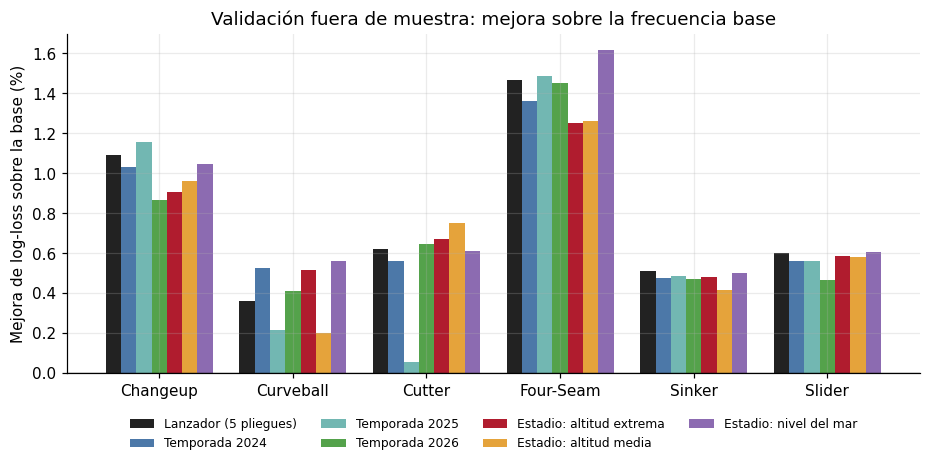

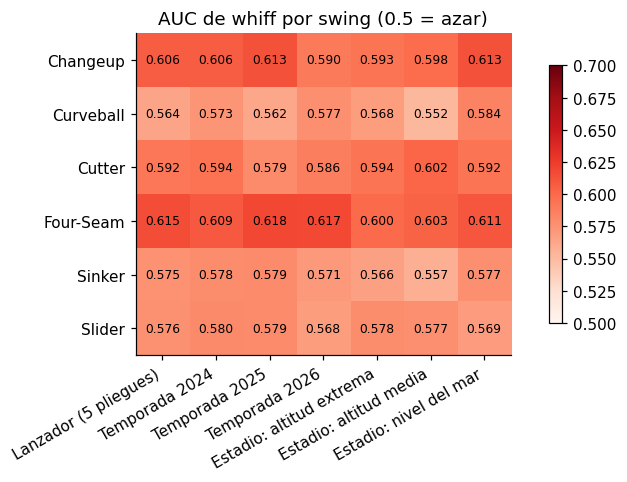

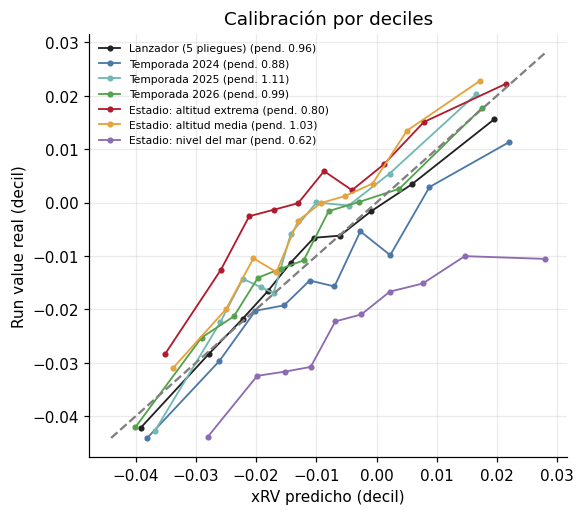

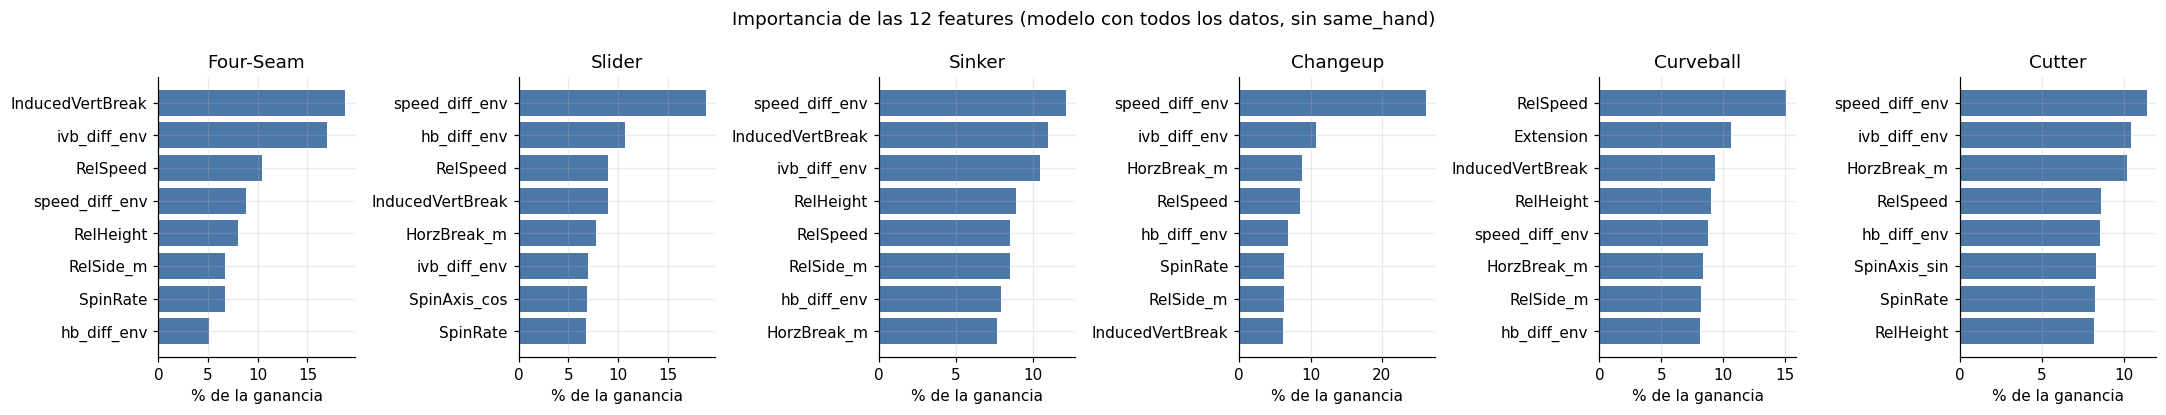

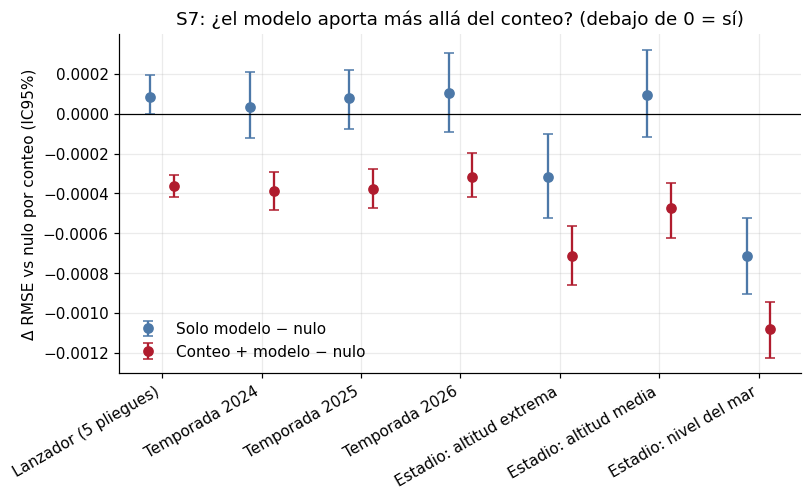

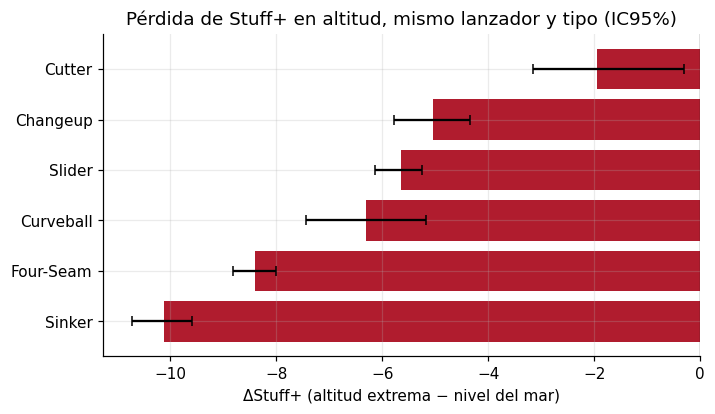

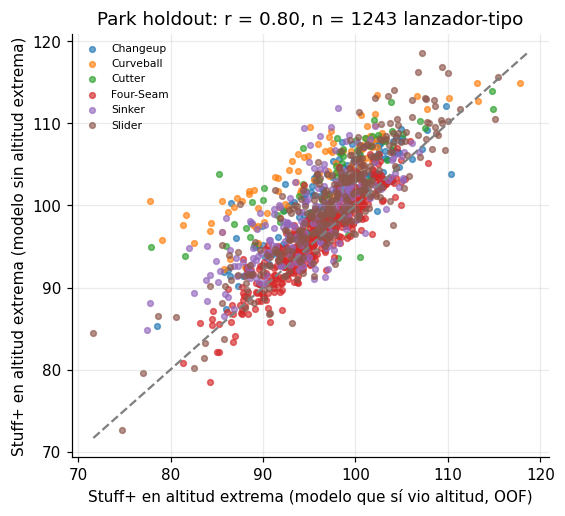

In [ ]:
SPLIT_COLORS = ["#222222", "#4C78A8", "#72B7B2", "#54A24B", ACCENT, "#E5A33B", "#8C6BB1"]
def save(fig, name):
    fig.savefig(f"{FIG_DIR}/{name}.png", bbox_inches="tight"); plt.show(); plt.close(fig)

# --- V1 mejora de log-loss por tipo y validación
piv = M.pivot(index="pitch_type", columns="split", values="improve_pct")[ORDER]
fig, ax = plt.subplots(figsize=(10, 4))
w = 0.8 / len(ORDER)
for i, s in enumerate(ORDER):
    ax.bar(np.arange(len(piv)) + i * w - 0.4 + w / 2, piv[s], w, label=s, color=SPLIT_COLORS[i])
ax.axhline(0, color="k", lw=.8); ax.set_xticks(range(len(piv))); ax.set_xticklabels(piv.index)
ax.set_ylabel("Mejora de log-loss sobre la base (%)"); ax.set_title("Validación fuera de muestra: mejora sobre la frecuencia base")
ax.legend(ncol=4, fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1)); save(fig, "V1_logloss_por_validacion")

# --- V2 AUC de whiff
pa = M.pivot(index="pitch_type", columns="split", values="auc_whiff")[ORDER]
fig, ax = plt.subplots(figsize=(9, 3.8)); im = ax.imshow(pa.values, cmap="Reds", vmin=.5, vmax=max(.7, np.nanmax(pa.values)))
ax.set_xticks(range(len(ORDER))); ax.set_xticklabels(ORDER, rotation=30, ha="right"); ax.set_yticks(range(len(pa))); ax.set_yticklabels(pa.index)
for i in range(pa.shape[0]):
    for j in range(pa.shape[1]): ax.text(j, i, f"{pa.values[i, j]:.3f}", ha="center", va="center", fontsize=8)
ax.grid(False); ax.set_title("AUC de whiff por swing (0.5 = azar)"); fig.colorbar(im, ax=ax, shrink=.8); save(fig, "V2_auc_whiff")

# --- V3 calibración por deciles
fig, ax = plt.subplots(figsize=(5.6, 5))
lo, hi = np.inf, -np.inf
for i, s in enumerate(ORDER):
    cal, slope = decile_calibration(ALL[ALL["split"] == s])
    ax.plot(cal["xrv"], cal["real"], "o-", ms=3, lw=1.2, color=SPLIT_COLORS[i], label=f"{s} (pend. {slope:.2f})")
    lo, hi = min(lo, cal[["xrv", "real"]].min().min()), max(hi, cal[["xrv", "real"]].max().max())
ax.plot([lo, hi], [lo, hi], "--", color="gray"); ax.set_xlabel("xRV predicho (decil)"); ax.set_ylabel("Run value real (decil)")
ax.set_title("Calibración por deciles"); ax.legend(fontsize=7, frameon=False); save(fig, "V3_calibracion")

# --- V4 importancia por ganancia
types = list(IMP["pitch_type"].unique())
fig, axes = plt.subplots(1, len(types), figsize=(3.3 * len(types), 3.8))
for ax, pt in zip(np.atleast_1d(axes), types):
    g = IMP[IMP["pitch_type"] == pt].nlargest(13, "gain_pct").iloc[::-1]
    ax.barh(g["feature"], g["gain_pct"], color="#4C78A8"); ax.set_title(pt); ax.set_xlabel("% de la ganancia")
fig.suptitle("Importancia de las 12 features (modelo con todos los datos, sin same_hand)"); fig.tight_layout(); save(fig, "V4_importancia_12features")

# --- V5 S7
fig, ax = plt.subplots(figsize=(8, 4)); x = np.arange(len(S7))
for off, key, lo_k, hi_k, lab, col in ((-.12, "d_modelo", "d_modelo_lo", "d_modelo_hi", "Solo modelo − nulo", "#4C78A8"),
                                       (.12, "d_conteo_modelo", "d_cm_lo", "d_cm_hi", "Conteo + modelo − nulo", ACCENT)):
    ax.errorbar(x + off, S7[key], yerr=[S7[key] - S7[lo_k], S7[hi_k] - S7[key]], fmt="o", capsize=3, color=col, label=lab)
ax.axhline(0, color="k", lw=.8); ax.set_xticks(x); ax.set_xticklabels(S7["split"], rotation=30, ha="right")
ax.set_ylabel("Δ RMSE vs nulo por conteo (IC95%)"); ax.set_title("S7: ¿el modelo aporta más allá del conteo? (debajo de 0 = sí)")
ax.legend(frameon=False); save(fig, "V5_s7_rmse")

# --- V6 ΔStuff+ por tipo
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(DELTA["pitch_type"], DELTA["delta_stuff"], xerr=[DELTA["delta_stuff"] - DELTA["lo"], DELTA["hi"] - DELTA["delta_stuff"]],
        color=ACCENT, capsize=3)
ax.axvline(0, color="k", lw=.8); ax.set_xlabel("ΔStuff+ (altitud extrema − nivel del mar)")
ax.set_title("Pérdida de Stuff+ en altitud, mismo lanzador y tipo (IC95%)"); save(fig, "V6_delta_stuff_por_tipo")

# --- V7 park holdout
fig, ax = plt.subplots(figsize=(5.6, 5))
for pt, g in PK.groupby("pt"): ax.scatter(g["oof"], g["sin_altitud"], s=14, alpha=.65, label=pt)
l, h = PK[["oof", "sin_altitud"]].min().min(), PK[["oof", "sin_altitud"]].max().max()
ax.plot([l, h], [l, h], "--", color="gray"); ax.set_xlabel("Stuff+ en altitud extrema (modelo que sí vio altitud, OOF)")
ax.set_ylabel("Stuff+ en altitud extrema (modelo sin altitud extrema)")
ax.set_title(f"Park holdout: r = {r_park:.2f}, n = {len(PK)} lanzador-tipo"); ax.legend(fontsize=7, frameon=False); save(fig, "V7_park_holdout")

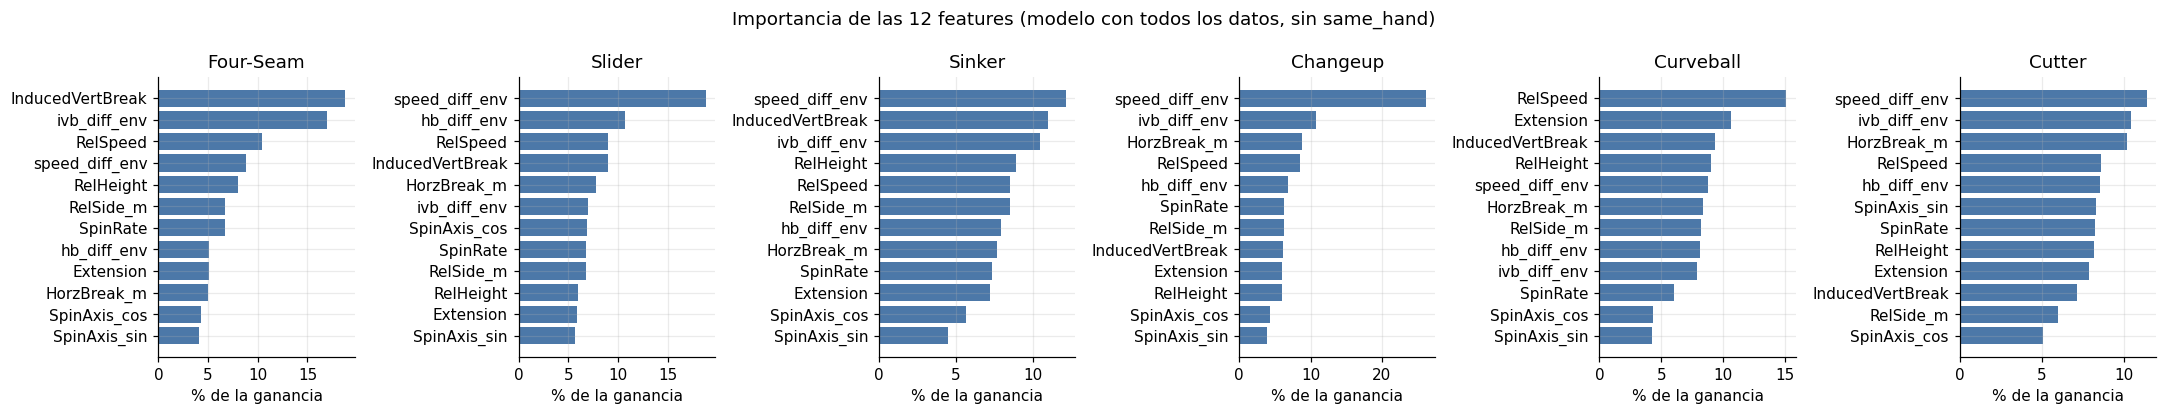

In [17]:
# --- V4 importancia por ganancia
types = list(IMP["pitch_type"].unique())
fig, axes = plt.subplots(1, len(types), figsize=(3.3 * len(types), 3.8))
for ax, pt in zip(np.atleast_1d(axes), types):
    g = IMP[IMP["pitch_type"] == pt].nlargest(13, "gain_pct").iloc[::-1]
    ax.barh(g["feature"], g["gain_pct"], color="#4C78A8"); ax.set_title(pt); ax.set_xlabel("% de la ganancia")
fig.suptitle("Importancia de las 12 features (modelo con todos los datos, sin same_hand)"); fig.tight_layout(); save(fig, "V4_importancia_12features")
plt.show()